# Doughnut Economics Analysis Report

## Στοιχεία Φοιτητή
- Ονοματεπώνυμο: Ζωή Γιαγλή


## Εισαγωγή

Στην παρούσα εργασία πραγματοποιείται ανάλυση δεδομένων τα οποία εξετάζουν την πρόοδο ως προς τη κάλυψη των αναγκών των ανθρώπων εντός των ορίων του πλανήτη για τη περίοδο 2000-2022. Οι δύο διαστάσεις που εξετάζονται είναι:

-Η κοινωνική θεμελίωση (social foundation), δηλαδή πόσοι άνθρωποι στερούνται βασικά αγαθά και αν η κατάσταση βελτιώνεται ή επιδεινώνεται με τη πάροδο του χρόνου.

-Το οικολογικό ταβάνι (ecological ceiling), δηλαδή πόσο η ανθρώπινη δραστηριότητα οδηγεί στην υπέρβαση των περιβαλλοντικών ορίων του πλανήτη. 

Η εργασία βασίζεται στο άρθρο των Andrew L. Fanning και Kate Raworth και στόχος της είναι η επεξεργασία, ανάλυση και οπτικοποίηση των σχετικών δεδομένων, ώστε να εξαχθούν συμπεράσματα για τη σχέση μεταξύ κοινωνικής ευημερίας και περιβαλλοντικής βιωσιμότητας.



## Βιβλιοθήκες

Για την υλοποίηση της ανάλυσης χρησιμοποιήθηκαν βιβλιοθήκες της Python για την επεξεργασία δεδομένων και την δημιουργία των γραφημάτων. Πιο συγκεκριμένα χρησιμοποιήθηκαν οι:

- **Pandas**: για την επεξεργασία των δεδομένων μέσω dataframes.
- **NumPy**: για αριθμητικούς υπολογισμούς και πράξεις με πίνακες.
- **Matplotlib**: για τη δημιουργία στατικών γραφημάτων.
- **Seaborn**: για τη δημιουργία στατικών γραφημάτων με πιο εκφραστικό API.
- **Plotly**: για τη δημιουργία διαδραστικών γραφημάτων (χρησιμοποιήθηκε για το doughnut plot).
- **Math**: για μαθηματικές συναρτήσεις.
- **os**: για διαχείριση διαδρομών και αρχείων.

Παρακάτω πραγματοποιείται η εισαγωγή των βιβλιοθηκών αυτών:



In [78]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
import plotly.graph_objects as go

plt.style.use("ggplot")

## Ορισμός Διαδρομής Δεδομένων

Παρακάτω γίνεται ο ορισμός του relative path προς τον φάκελο Clean Data που περιέχει τα δεδομένα που επεξεργάζονται στην εργασία.

In [79]:
DATA_PATH = "data/a-fanning-doughnut-v3-a0460e5/Analysis-Final/cleanData/"


## The Social Foundation and Its Indicators of Shortfall

Στο παρόν στάδιο πραγματοποιείται η επεξεργασία των δεδομένων που αφορούν την κοινωνική θεμελίωση. Πιο συγκεκριμένα, δημιουργείται ένας πίνακας που για κάθε κοινωνικό δείκτη παρουσιάζει σε ποια κοινωνική διάσταση ανήκει αυτός ο δείκτης, την περιγραφή του δείκτη, την πρώτη και τη τελευταία διαθέσιμη χρονιά για αυτόν τον δείκτη και τις αντίστοιχες τιμές του ελλείμματος κάλυψης των ανθρώπινων αναγκών (shortfall) για αυτές τις δύο χρονιές. Συνολικά αναλύονται 21 δείκτες, όπως η πρόσβαση στο διαδίκτυο, στην εκπαίδευση και στο νερό.

#### Φόρτωση και συγχώνευση των κοινωνικών δεδομένων

Αρχικά φορτώνουμε τα αρχεία που περιέχουν τους επιθυμητούς δείκτες, δηλαδή αυτούς της κοινωνικής θεμελίωσης. Χρησιμοποιούμε το relative path που ορίστηκε πρίν και το πρόθεμα 'soc-' ώστε να τα διακρίνουμε από τα υπόλοιπα αρχεία. Τα αρχεία αυτά διαβάζονται και συγχωνεύονται σε ένα κοινό data frame. 

In [80]:
social_files = sorted([f for f in os.listdir(DATA_PATH) if f.startswith("soc-")])

social = pd.concat(
    [pd.read_csv(DATA_PATH + f) for f in social_files],
    ignore_index=True
)

#### Επιλογή δεδομένων σε παγκόσμιο επίπεδο

Μετά τη συγχώνευση των αρχείων επιλέγονται οι εγγραφές που αφορούν το σύνολο του παγκόσμιου πληθυσμού, καθώς θέλουμε να εστιάσουμε μόνο σε αυτούς.

In [81]:
social = social.loc[social["group"] == "World"].copy()

#### Επιλογή των κοινωνικών δεικτών

Σε αυτό το στάδιο ορίζεται ρητά το υποσύνολο των δεικτών που θα συμπεριληφθούν στην ανάλυση.

In [82]:
selected_indicators = [
    "internet",
    "publicTrans",
    "adultLiteracy",
    "secondarySchool",
    "energyAccess",
    "energyIndoor",
    "genderGapIndex",
    "foodInsecurity",
    "undernourishment",
    "UHCindex",
    "under5death",
    "urbanSlums",
    "societalPoverty",
    "youthNEET",
    "controlCorruption",
    "homicideOver5",
    "govRegimes",
    "palma",
    "socialSupport",
    "drinkingH2O",
    "sanitation",
]

social = social.loc[social["indicator"].isin(selected_indicators)].copy()

#### Μετατροπή των δεικτών σε κοινή λογική 
Έπειτα, πραγματοποιείται η μετατροπή των δεικτών σε μια κοινή κλίμακα. Αυτό είναι απαραίτητο καθώς κάθε δείκτης εκφράζει κάτι διαφορετικό, και έτσι σε ορισμένες περιπτώσεις μια υψηλή τιμή είναι θετική ενώ σε άλλες είναι αρνητική. Ορίζουμε δύο κατηγορίες:

-Δείκτες που πρέπει να αντιστραφούν (invert 100): αυτοί οι δείκτες μετρούν ποσοστό επιτυχίας οπότε μετατρέπονται σε ποσοστό ελλείμματος.

-Δείκτες που πρέπει να πολλαπλασιαστούν επί 100 (multiply 100): αυτοί οι δείκτες πρέπει να μετατραπούν σε ποσοστά.


In [83]:
invert_100 = {
    "internet",
    "publicTrans",
    "adultLiteracy",
    "secondarySchool",
    "energyAccess",
    "energyIndoor",
    "drinkingH2O",
    "sanitation",
}

multiply_100 = {
    "genderGapIndex",
    "societalPoverty",
}

#### Ορισμός συνάρτησης υπολογισμού του shortfall
Σε αυτό το βήμα ορίζεται η συνάρτηση μετασχηματισμού του κάθε δείκτη. Έχει ως ορίσματα το όνομα του δείκτη και την τιμή του και μετατρέπει τους δείκτες ώστε να εκφράζουν το "shortfall". Αρχικά, ελέγχει αν η τιμή του δείκτη είναι κενή και στην περίπτωση αυτή επιστρέφει κενή τιμή. Αν ο δείκτης ανήκει στη κατηγορία "invert 100" υπολογίζει το κοινωνικό έλλειμμα αφαιρώντας την τιμή του από το 100. Και τέλος, αν ο δείκτης ανήκει στην κατηγορία "multiply 100" η τιμή του μετατρέπεται σε ποσοστό μέσω πολλαπλασιασμού επί 100.


In [84]:
def compute_shortfall(indicator, value):
    if pd.isna(value):
        return pd.NA
    if indicator in invert_100:
        return 100 - value
    elif indicator in multiply_100:
        return 100 * value
    else:
        return value

#### Υπολογισμός και καθαρισμός της μεταβλητής shortfall
Στη συνέχεια, η συνάρτηση που ορίστηκε παραπάνω εφαρμόζεται σε κάθε γραμμή του συνόλου δεδομένων και δημιουργείται μια νέα στήλη όπου αποθηκεύονται τα αποτελέσματα ("shortfall_value").΄Επειτα μετατρέπεται η νέα στήλη σε αριθμητική μορφή. Σε περίπτωση που κάποια τιμή δε μπορεί να μετατραπεί σε αριθμό, ορίζεται ως NaN. Όσες γραμμές είναι κενές διαγράφονται από το σύνολο δεδομένων, ώστε οι επόμενοι υπολογισμοί να γίνουν μόνο σε έγκυρες αριθμητικές τιμές.

In [85]:
social["shortfall_value"] = social.apply(
    lambda row: compute_shortfall(row["indicator"], row["value"]),
    axis=1
)

social["shortfall_value"] = pd.to_numeric(social["shortfall_value"], errors="coerce")
social = social.dropna(subset=["shortfall_value"]).copy()

#### Μετονομασία διαστάσεων και δεικτών
Πραγματοποιείται μετονομασία των διαστάσεων και των δεικτών για να βελτιωθεί η ερμηνευσιμότητα και αναγνωσιμότητα των αποτελεσμάτων. 

In [86]:
dimension_labels = {
    "connectivity": "Connectivity",
    "education": "Education",
    "energy": "Energy",
    "equality": "Equality",
    "food": "Food",
    "health": "Health",
    "housing": "Housing",
    "income and work": "Income and work",
    "peace and justice": "Peace and justice",
    "political voice": "Political voice",
    "social cohesion": "Social cohesion",
    "water": "Water",
}

indicator_labels = {
    "internet": "Population not accessing the internet",
    "publicTrans": "Urban population lacking convenient access to public transport",
    "adultLiteracy": "Adult population (aged 15+ years) who are illiterate",
    "secondarySchool": "Young adult population (aged 21-23 years) with incomplete upper secondary education",
    "energyAccess": "Population lacking access to electricity",
    "energyIndoor": "Population lacking access to clean fuels and technologies for cooking, heating and lighting",
    "genderGapIndex": "Population-weighted score on the Gender Inequality Index (global gap between women and men in terms of reproductive health, empowerment and employment)",
    "foodInsecurity": "Population with moderate to severe food insecurity",
    "undernourishment": "Population undernourished",
    "UHCindex": "Population living in countries without high coverage of essential health services (Universal Health Coverage Index score less than 60 out of 100)",
    "under5death": "Population living in countries with under-5 mortality rate exceeding 25 per 1,000 live births",
    "urbanSlums": "Urban population living in slums or informal settlements",
    "societalPoverty": "Population living below the societal poverty line, set at half their country's median household income or at least $15 a day",
    "youthNEET": "Population of young people (aged 15-24 years) not in employment, education or training",
    "controlCorruption": "Population stating that they perceive widespread corruption in government and business",
    "homicideOver5": "Population living in countries with a homicide rate of 5 or more per 100,000",
    "govRegimes": "Population living in countries governed by an autocratic regime",
    "palma": "Population living in countries with a Palma ratio of 2 or more (the income share of the richest 10% of people relative to the poorest 40%)",
    "socialSupport": "Population stating that they are without someone to count on in times of trouble",
    "drinkingH2O": "Population lacking access to safely managed drinking water",
    "sanitation": "Population lacking access to safely managed sanitation",
}

social["dimension_display"] = social["dimension"].map(dimension_labels)
social["indicator_display"] = social["indicator"].map(indicator_labels)

#### Δημιουργία συγκεντρωτικού πίνακα 
Σε αυτό το σημείο το dataset ταξινομείται με βάση τη διάσταση, τον δείκτη και τη χρονολογία και ομαδοποιείται με βάση τη διάσταση και τον δείκτη. Για κάθε ομάδα κρατάμε μόνο την πρώτη και τελευταιά χρονιά, και αντίστοιχα τις τιμές του "shortfall" για αυτές τις χρονιές. Οι τιμές στρογγυλοποιούνται σε δύο δεκαδικά ψηφία.

In [87]:
summary = (
    social
    .sort_values(["dimension_display", "indicator_display", "date"])
    .groupby(["dimension_display", "indicator_display"], as_index=False)
    .agg(
        date_first=("date", "first"),
        date_last=("date", "last"),
        value_first=("shortfall_value", "first"),
        value_last=("shortfall_value", "last"),
    )
)

summary["value_first"] = summary["value_first"].round(2)
summary["value_last"] = summary["value_last"].round(2)

#### Ταξινόμηση των αποτελεσμάτων
Έπειτα όλες οι μοναδικές διαστάσεις ταξινομούνται αλφαβητικά και η στήλη "dimension_display" μετατρέπεται σε κατηγορική μεταβλητή με καθορισμένη σειρά, ώστε να υπάρχει σταθερή σειρά εμφάνισης στον πίνακα. Η τελική ταξινόμηση του πίνακα προκύπτει από τη διάσταση και το όνομα του δείκτη.

In [88]:
dimension_order = sorted(summary["dimension_display"].dropna().unique())

summary["dimension_display"] = pd.Categorical(
    summary["dimension_display"],
    categories=dimension_order,
    ordered=True
)

summary = summary.sort_values(["dimension_display", "indicator_display"]).reset_index(drop=True)

#### Δημιουργία πολυεπίπεδων ονομάτων στηλών

In [89]:
table1 = summary.copy()
table1.columns = pd.MultiIndex.from_tuples([
    ("dimension", ""),
    ("indicator", ""),
    ("date", "first"),
    ("date", "last"),
    ("value", "first"),
    ("value", "last"),
])

#### Μορφοποίηση του πίνακα
Τέλος, πραγματοποιείται η μορφοποίηση του πίνακα όπου ρυθμίζονται στοιχεία όπως η στοίχιση και τα περιθώρια και γίνεται η εμφάνιση του πίνακα.

In [90]:
styled_table1 = (
    table1.style
    .format({
        ("value", "first"): "{:.2f}",
        ("value", "last"): "{:.2f}",
    })
    .hide(axis="index")
    .set_table_styles([
        {"selector": "table", "props": [
            ("border-collapse", "separate"),
            ("border-spacing", "0"),
            ("width", "82%"),
            ("margin-left", "auto"),
            ("margin-right", "auto"),
            ("font-size", "15px")
        ]},

        {"selector": "thead th", "props": [
            ("text-align", "center"),
            ("font-weight", "bold"),
            ("padding", "8px 10px"),
            ("border", "none"),
            ("border-bottom", "1px solid #999"),
            ("background-color", "white")
        ]},

        {"selector": "tbody td", "props": [
            ("padding", "8px 10px"),
            ("border", "none"),
            ("vertical-align", "top"),
            ("text-align", "left")
        ]},

        {"selector": "tbody tr", "props": [
            ("border", "none")
        ]},
    ])
)

styled_table1

## The Ecological Ceiling and Its Indicators of Overshoot

Στο παρόν στάδιο πραγματοποιείται η επεξεργασία των δεδομένων που αφορούν το οικολογικό ταβάνι (ecological ceiling). Πιο συγκεκριμένα, δημιουργείται ένας πίνακας που για κάθε οικολογικό δείκτη παρουσιάζει τη διάσταση στην οποία ανήκει, την περιγραφή του δείκτη, την πρώτη και την τελευταία διαθέσιμη χρονιά για αυτόν, καθώς και τις αντίστοιχες τιμές του δείκτη για τις δύο αυτές χρονιές. Συνολικά αναλύονται 13 δείκτες, οι οποίοι καλύπτουν βασικές περιβαλλοντικές διαστάσεις, όπως η κλιματική αλλαγή, η ρύπανση του αέρα, η διατάραξη των κύκλων αζώτου και φωσφόρου, η οξίνιση των ωκεανών και η αποψίλωση των δασών.
Ο πίνακας αυτός επιτρέπει μια συνοπτική αποτύπωση της εξέλιξης βασικών οικολογικών μεγεθών μέσα στον χρόνο και συμβάλλει στην κατανόηση του κατά πόσο η ανθρώπινη δραστηριότητα παραμένει εντός ή υπερβαίνει τα πλανητικά όρια.

#### Φόρτωση και επιλογή των οικολογικών δεδομένων
Αρχικά φορτώνουμε τα αρχεία που περιέχουν τους δείκτες που σχετίζονται με το οικολογικό ταβάνι. Χρησιμοποιούμε το relative path που ορίστηκε πριν και το πρόθεμα 'eco-' ώστε να τα διακρίνουμε από τα υπόλοιπα αρχεία. Τα αρχεία αυτά διαβάζονται και συγχωνεύονται σε ένα κοινό data frame. Από αυτό το σύνολο κρατάμε μόνο τις εγγραφές που αφορούν το παγκόσμιο επίπεδο και επιλέγουμε ποιοι συγκεκριμένοι δείκτες θα εμφανίζονται στον πίνακα.

In [91]:
eco_files = sorted([f for f in os.listdir(DATA_PATH) if f.startswith("eco-")])

eco = pd.concat(
    [pd.read_csv(DATA_PATH + f) for f in eco_files],
    ignore_index=True
)

eco = eco.loc[eco["group"] == "World"].copy()

selected_eco_indicators = [
    "interhemAOD",
    "extinction1900",
    "hanppGtC",
    "chemicalsMt",
    "co2_ppm",
    "erf_wm2",
    "blueDev",
    "soilDev",
    "forestAreaMKM2",
    "nitrogenMt",
    "phosphorusMt",
    "omega_a",
    "totalOzone",
]

eco = eco.loc[eco["indicator"].isin(selected_eco_indicators)].copy()

#### Καθαρισμός τιμών 
Η στήλη "value" μετατρέπεται σε αριθμητική μορφή και οι μη έγκυρες ή ελλιπείς τιμές απομακρύνονται από το σύνολο δεδομένων, ώστε να είναι δυνατή η σύγκριση των δεδομένων.

In [92]:
eco["value"] = pd.to_numeric(eco["value"], errors="coerce")
eco = eco.dropna(subset=["value"]).copy()

#### Μετονομασία διαστάσεων και δεικτών
Οι οικολογικές διαστάσεις και οι δείκτες μετονομάζονται ώστε ο τελικός πίνακας να ειναι ευανάγνωστος και σαφής.

In [93]:
eco_dimension_labels = {
    "air pollution": "Air pollution",
    "biodiversity breakdown": "Biodiversity breakdown",
    "chemical pollution": "Chemical pollution",
    "climate change": "Climate change",
    "freshwater disruption": "Freshwater disruption",
    "land conversion": "Land conversion",
    "nutrient pollution": "Nutrient pollution",
    "ocean acidification": "Ocean acidification",
    "ozone depletion": "Ozone depletion",
}

eco_indicator_labels = {
    "interhemAOD": "Arithmetic Error Asymmetry between Earth's hemispheres of sunlight reaching the surface, owing to differences in atmospheric particle concentration (at most 0.1 inter-hemispheric difference in Aerosol Optical Depth)",
    "extinction1900": "Rate of species extinctions per million species years (at most 10 E/MSY)",
    "hanppGtC": "Human appropriation of net primary productivity, billions of tonnes of carbon per year (at most 10% of 55.9 Gt C)",
    "chemicalsMt": "Production of hazardous chemicals, millions of tonnes per year (at most 5% of the 1,200 Mt of total chemicals produced in year 2000)",
    "co2_ppm": "Atmospheric carbon dioxide concentration, parts per million (at most 350 ppm CO2)",
    "erf_wm2": "Human-induced radiative forcing at the top of the atmosphere, Watt per square metre (at most 1 W m**(-2))",
    "blueDev": "Proportion of land area with human-induced disturbance of blue-water flow deviating from Holocene variability (at most 10.2%)",
    "soilDev": "Proportion of land area with root-zone soil moisture deviating from Holocene variability (at most 11.1%)",
    "forestAreaMKM2": "Area of forested land as a proportion of forest-covered land before human alteration (at least 75% of 64 million square kilometres)",
    "nitrogenMt": "Nitrogen applied to land as fertilizer, millions of tonnes per year (at most 62 Mt per year)",
    "phosphorusMt": "Phosphorus applied to land as fertilizer, millions of tonnes per year (at most 6.2 Mt per year)",
    "omega_a": "Average saturation state of aragonite at the ocean surface (at least 80% of pre-industrial saturation state of 3.44 Ωarag)",
    "totalOzone": "Concentration of ozone in the stratosphere, Dobson units (at most 5% decrease with respect to 1964-1980 value of 290 DU)",
}

eco["dimension_display"] = eco["dimension"].map(eco_dimension_labels)
eco["indicator_display"] = eco["indicator"].map(eco_indicator_labels)

#### Δημιουργία συγκεντρωτικού πίνακα
Στη συνέχεια, δημιουργείται ο συγκεντρωτικός πίνακας για τη σύγκριση των οικολογικών δεικτών. Τα δεδομένα ταξινομούνται ως προς τη διάσταση, τον δείκτη και τη χρονολογία και ομαδοποιούνται με βάση τη διάσταση και τον δείκτη. Κρατάμε μόνο τις τιμές της αρχικής και τελικής διαθέσιμης χρονικής παρατήρησης. Οι τιμές στρογγυλοποιούνται σε δύο δεκαδικά ψηφία. Τέλος, ορίζεται μια συγκεκριμένη σειρά εμφάνισης για τις διαστάσεις και τους δείκτες και δημιουργούνται πολυεπίπεδα ονόματα στηλών.

In [94]:
eco_summary = (
    eco
    .sort_values(["dimension_display", "indicator_display", "date"])
    .groupby(["dimension_display", "indicator_display"], as_index=False)
    .agg(
        date_first=("date", "first"),
        date_last=("date", "last"),
        value_first=("value", "first"),
        value_last=("value", "last"),
    )
)

eco_summary["value_first"] = eco_summary["value_first"].round(2)
eco_summary["value_last"] = eco_summary["value_last"].round(2)

eco_dimension_order = [
    "Air pollution",
    "Biodiversity breakdown",
    "Chemical pollution",
    "Climate change",
    "Freshwater disruption",
    "Land conversion",
    "Nutrient pollution",
    "Ocean acidification",
    "Ozone depletion",
]

eco_indicator_order = [
    "Arithmetic Error Asymmetry between Earth's hemispheres of sunlight reaching the surface, owing to differences in atmospheric particle concentration (at most 0.1 inter-hemispheric difference in Aerosol Optical Depth)",
    "Rate of species extinctions per million species years (at most 10 E/MSY)",
    "Human appropriation of net primary productivity, billions of tonnes of carbon per year (at most 10% of 55.9 Gt C)",
    "Production of hazardous chemicals, millions of tonnes per year (at most 5% of the 1,200 Mt of total chemicals produced in year 2000)",
    "Atmospheric carbon dioxide concentration, parts per million (at most 350 ppm CO2)",
    "Human-induced radiative forcing at the top of the atmosphere, Watt per square metre (at most 1 W m**(-2))",
    "Proportion of land area with human-induced disturbance of blue-water flow deviating from Holocene variability (at most 10.2%)",
    "Proportion of land area with root-zone soil moisture deviating from Holocene variability (at most 11.1%)",
    "Area of forested land as a proportion of forest-covered land before human alteration (at least 75% of 64 million square kilometres)",
    "Nitrogen applied to land as fertilizer, millions of tonnes per year (at most 62 Mt per year)",
    "Phosphorus applied to land as fertilizer, millions of tonnes per year (at most 6.2 Mt per year)",
    "Average saturation state of aragonite at the ocean surface (at least 80% of pre-industrial saturation state of 3.44 Ωarag)",
    "Concentration of ozone in the stratosphere, Dobson units (at most 5% decrease with respect to 1964-1980 value of 290 DU)",
]

eco_summary["dimension_display"] = pd.Categorical(
    eco_summary["dimension_display"],
    categories=eco_dimension_order,
    ordered=True
)

eco_summary["indicator_display"] = pd.Categorical(
    eco_summary["indicator_display"],
    categories=eco_indicator_order,
    ordered=True
)

eco_summary = eco_summary.sort_values(["dimension_display", "indicator_display"]).reset_index(drop=True)


table2 = eco_summary.copy()
table2.columns = pd.MultiIndex.from_tuples([
    ("dimension", ""),
    ("indicator", ""),
    ("date", "first"),
    ("date", "last"),
    ("value", "first"),
    ("value", "last"),
])

#### Μορφοποίηση του πίνακα
Στο τελικό στάδιο πραγματοποιείται η μορφοποίηση του πίνακα όπου ρυθμίζονται τα στοιχεία παρουσίασής του και εμφανίζεται το τελικό αποτέλεσμα.

In [95]:

styled_table2 = (
    table2.style
    .format({
        ("value", "first"): "{:.2f}",
        ("value", "last"): "{:.2f}",
    })
    .hide(axis="index")
    .set_table_styles([
        {"selector": "table", "props": [
            ("border-collapse", "separate"),
            ("border-spacing", "0"),
            ("width", "82%"),
            ("margin-left", "auto"),
            ("margin-right", "auto"),
            ("font-size", "15px")
        ]},

        {"selector": "thead th", "props": [
            ("text-align", "center"),
            ("font-weight", "bold"),
            ("padding", "8px 10px"),
            ("border", "none"),
            ("border-bottom", "1px solid #999"),
            ("background-color", "white")
        ]},

        {"selector": "tbody td", "props": [
            ("padding", "8px 10px"),
            ("border", "none"),
            ("vertical-align", "top"),
            ("text-align", "left")
        ]},

        {"selector": "tbody tr", "props": [
            ("border", "none")
        ]},
    ])
)

styled_table2

## Country Clusters

Σε αυτό το στάδιο εξετάζονται οι διαφορές μεταξύ ομάδων χωρών ως προς την κοινωνική υστέρηση (social shortfall) και την οικολογική υπέρβαση (ecological overshoot). Οι χώρες κατατάσσονται σε τρεις εισοδηματικές κατηγορίες: Bottom 40 (χαμηλότερο επίπεδο εισοδήματος), Middle 40 (μεσαίο επίπεδο εισοδήματος) & Top 20 (υψηλότερο επίπεδο εισοδήματος).
Πιο συγκεκριμένα, για κάθε ομάδα χωρών παρουσιάζονται δύο διαγράμματα:
1. η οικολογική υπέρβαση σε επιλεγμένους περιβαλλοντικούς δείκτες, η οποία υπολογίζεται με βάση τα πλανητικά όρια (planetary boundaries)
2. η κοινωνική υστέρηση σε βασικούς δείκτες, η οποία εκφράζει το ποσοστό του πληθυσμού που δε καλύπτει βασικές ανθρώπινες ανάγκες.

Η ανάλυση αυτή επιτρέπει την εξαγωγή συμπερασμάτων σχετικά με κατά πόσο το επίπεδο εισοδήματος μιας χώρας επηρεάζει τόσο την κοινωνική της ανάπτυξη όσο και τον βαθμό περιβαλλοντικής επιβάρυνσης που προκαλεί.

## Ecological Overshoot trellis plot

#### Φόρτωση και επιλογή των δεδομένων του διαγράμματος

Αρχικά, φορτώνονται τα επεξεργασμένα δεδομένα που αφορούν τις ομάδες χωρών για το έτος 2017. Από το αρχικό σύνολο δεδομένων διατηρούνται μόνο οι παρατηρήσεις που ανήκουν στο οικολογικό πεδίο (ecological domain), μόνο οι επιλεγμένοι δείκτες οικολογικού αποτυπώματος (footprint indicators) και μόνο οι τρεις εισοδηματικές κατηγορίες χωρών: Bottom-40, Middle-40 και Top-20.


In [96]:
df = pd.read_csv("data/a-fanning-doughnut-v3-a0460e5/Analysis-Final/myData/12_20250515_groupDoughnutData_2017.csv")

footprint_indicators = [
    "blueH2O_footprint",
    "co2_footprint",
    "hanpp_footprint",
    "N_footprint",
    "P_footprint",
    "species_footprint",
]

groups = ["Bottom-40", "Middle-40", "Top-20"]

df_plot = df.loc[
    (df["domain"] == "ecological") &
    (df["indicator"].isin(footprint_indicators)) &
    (df["group"].isin(groups)),
    ["indicator", "group", "date", "value", "boundary", "shortfallOvershoot_pct"]
].copy()

#### Μεταβλητή οικολογικής υπέρβασης
Στη συνέχεια πραγματοποιείται ο καθορισμός της μεταβλητής που εκφράζει την οικολογική υπέρβαση σε ποσοστό. Η στήλη "shortfallOvershoot_pct" μετατρέπεται σε αριθμητική μορφή, οι μη έγκυροι αριθμοί γίνονται NaN και αφαιρούνται οι κενές τιμές. Έπειτα, μετατρέπουμε τις αρνητικές τιμές σε 0, ώστε στο γράφημα να εμφανίζεται μόνο η υπέρβαση και όχι αρνητικοί αριθμοί.


In [97]:

df_plot["shortfallOvershoot_pct"] = pd.to_numeric(df_plot["shortfallOvershoot_pct"], errors="coerce")
df_plot = df_plot.dropna(subset=["shortfallOvershoot_pct"]).copy()
df_plot["overshoot"] = np.maximum(0, df_plot["shortfallOvershoot_pct"])

#### Ορισμός τίτλων, χρωμάτων και σειράς εμφάνισης
Ορίζονται σαφείς τίτλοι για κάθε δείκτη και ένα σταθερό χρώμα για κάθε εισοδηματική ομάδα, ώστε το διάγραμμα να είναι εύκολα κατανοητό.

In [98]:
titles = {
    "blueH2O_footprint": "Blue water footprint",
    "co2_footprint": "Carbon footprint",
    "hanpp_footprint": "HANPP footprint",
    "N_footprint": "Nitrogen footprint",
    "P_footprint": "Phosphorus footprint",
    "species_footprint": "Species-loss footprint"
}

colors = {
    "Bottom-40": "#F2D300",
    "Middle-40": "#C9B4CE",
    "Top-20": "#4E84B3"
}

order = [
    "blueH2O_footprint",
    "co2_footprint",
    "hanpp_footprint",
    "N_footprint",
    "P_footprint",
    "species_footprint"
]

#### Δημιουργία του trellis plot

Στο στάδιο αυτό δημιουργείται το τελικό διάγραμμα που αποτελείται από έξι υποδιαγράμματα, ένα για κάθε επιλεγμένο δείκτη οικολογικού αποτυπώματος. Σε κάθε υποδιάγραμμα παρουσιάζονται τρεις μπάρες που αντιστοιχούν στις τρεις εισοδηματικές κατηγορίες που έχουμε ορίσει παραπάνω.
Για κάθε δείκτη τα δεδομένα αναδιατάσσονται ώστε οι ομάδες χωρών να εμφανίζονται με σταθερή σειρά, κάτι που διευκολύνει τη σύγκριση μεταξύ των υποδιαγραμμάτων. Παράλληλα, όλοι οι κατακόρυφοι άξονες διατηρούν κοινή κλίμακα, ώστε οι διαφορές μεταξύ δεικτών και ομάδων να είναι άμεσα ορατές.
Τέλος, ρυθμίζονται τα περιθώρια και οι αποστάσεις μεταξύ των υποδιαγραμμάτων για να είναι ευανάγνωστο το ολοκληρωμένο σχήμα


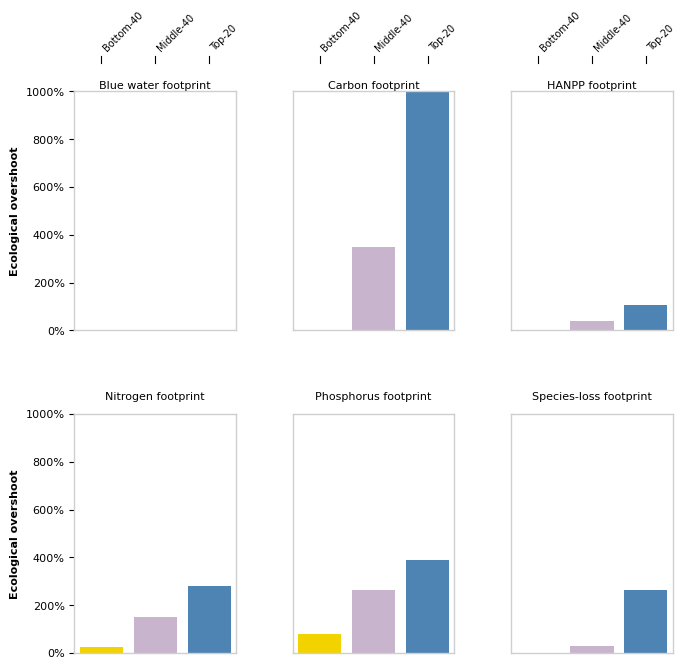

In [99]:
fig, axes = plt.subplots(2, 3, figsize=(6.8, 7.2), dpi=100)
axes = axes.flatten()

xpos_axes = [1/6, 0.5, 5/6]

for i, ind in enumerate(order):
    ax = axes[i]

    sub = (
        df_plot[df_plot["indicator"] == ind]
        .set_index("group")
        .reindex(groups)
    )

    x = np.arange(len(groups))

    ax.bar(
        x,
        sub["overshoot"],
        color=[colors[g] for g in groups],
        width=0.8
    )

    ax.set_xlim(-0.5, 2.5)
    ax.set_ylim(0, 1000)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v)}%"))

    if i % 3 == 0:
        ax.set_ylabel("Ecological overshoot", fontsize=8, weight="bold", color="black")
        ax.tick_params(axis="y", labelsize=8, colors="black", left=True, labelleft=True)
    else:
        ax.tick_params(axis="y", left=False, labelleft=False)

    ax.set_xticks([])

    if i < 3:
        for xa, lab in zip(xpos_axes, groups):
            ax.text(
                xa, 1.16, lab,
                transform=ax.transAxes,
                rotation=45,
                ha="left",
                va="bottom",
                fontsize=7,
                color="black",
                clip_on=False
            )

        for xa in xpos_axes:
            ax.plot(
                [xa, xa], [1.15, 1.12],
                transform=ax.transAxes,
                color="black",
                linewidth=0.8,
                clip_on=False
            )

        ax.text(
            0.5, 1.005, titles[ind],
            transform=ax.transAxes,
            ha="center",
            va="bottom",
            fontsize=8,
            color="black",
            clip_on=False
        )
    else:
        ax.text(
            0.5, 1.05, titles[ind],
            transform=ax.transAxes,
            ha="center",
            va="bottom",
            fontsize=8,
            color="black",
            clip_on=False
        )

    ax.grid(False)
    ax.set_facecolor("white")

    for spine in ax.spines.values():
        spine.set_color("#cfcfcf")
        spine.set_linewidth(1)

plt.subplots_adjust(
    left=0.10,
    right=0.98,
    top=0.88,
    bottom=0.10,
    wspace=0.35,
    hspace=0.35
)

plt.show()

## Social Shortfall trellis plot

#### Φόρτωση δεδομένων
Αρχικά φορτώνονται όλα τα καθαρισμένα δεδομένα που αφορούν την κοινωνική θεμελίωση ("soc-") από το relative path που έχει οριστεί στην αρχή του notebook και ενώνονται σε ένα ενιαίο data frame. Στη συνέχεια εφαρμόζονται οι ίδιοι μετασχηματισμοί που χρησιμοποιούνται και στα βασικά scripts του project, ώστε οι επιλεγμένοι κοινωνικοί δείκτες να αποκτήσουν κοινή ερμηνεία ως δείκτες υστέρησης (shortfall). Δηλαδή, σε περιπτώσεις όπου οι αρχικές τιμές εκφράζουν ποσοστό κάλυψης μιας ανάγκης (π.χ. adult literacy), μετατρέπεται η τιμή μέσω της πράξης '100-value', ώστε οι τελικές τιμές να εκφράζουν το ποσοστό του πληθυσμού που στερείται το αντίστοιχο αγαθό ή υπηρεσία (π.χ. adult illiteracy). Σε περιπτώσεις όπου οι τιμές δίνονται σε μορφή αναλογίας  πραγματοποιείται μετατροπή σε ποσοστό με πολλαπλασιασμό επί 100 με τη πράξη 'value * 100'.Τέλος, διατηρούνται μόνο οι δείκτες που είναι κατάλληλοι για τη συγκεκριμένη οπτικοποίηση.

In [100]:
social_files = sorted([f for f in os.listdir(DATA_PATH) if f.startswith("soc-")])

soc = pd.concat(
    [pd.read_csv(DATA_PATH + f) for f in social_files],
    ignore_index=True
)

soc = soc.copy()

soc.loc[soc["indicator"].isin(["adultLiteracy", "secondarySchool"]), "value"] = (
    100 - soc.loc[soc["indicator"].isin(["adultLiteracy", "secondarySchool"]), "value"]
)
soc.loc[soc["indicator"].isin(["drinkingH2O", "sanitation"]), "value"] = (
    100 - soc.loc[soc["indicator"].isin(["drinkingH2O", "sanitation"]), "value"]
)
soc.loc[soc["indicator"].isin(["energyAccess", "energyIndoor"]), "value"] = (
    100 - soc.loc[soc["indicator"].isin(["energyAccess", "energyIndoor"]), "value"]
)
soc.loc[soc["indicator"].isin(["publicTrans", "internet"]), "value"] = (
    100 - soc.loc[soc["indicator"].isin(["publicTrans", "internet"]), "value"]
)
soc.loc[soc["indicator"] == "genderGapIndex", "value"] = (
    soc.loc[soc["indicator"] == "genderGapIndex", "value"] * 100
)
soc.loc[soc["indicator"] == "societalPoverty", "value"] = (
    soc.loc[soc["indicator"] == "societalPoverty", "value"] * 100
)

# housing: keep only urban slums
soc = soc.loc[~((soc["dimension"] == "housing") & (soc["indicator"] != "urbanSlums"))].copy()

# exclude racial inequality
soc = soc.loc[soc["indicator"] != "racialInequality"].copy()

#### Επιλογή ομάδων και τελευταίας διαθέσιμης χρονιάς
Παρόμοια με το προηγούμενο διάγραμμα, χωρίζουμε τις ομάδες με βάση το οικονομικό τους  επίπεδο (Bottom-40, Middle-40, Top-20). Έπειτα, μετατρέπονται οι τιμές σε αριθμητικές και αφαιρούμε τυχόν κενές ή ελλιπείς εγγραφές. Για κάθε συνδυασμό δείκτη και ομάδας χωρών κρατάμε μόνο τη τελευταία διαθέσιμη χρονιά.

In [101]:
groups = ["Bottom-40", "Middle-40", "Top-20"]

soc_plot = soc.loc[
    soc["group"].isin(groups),
    ["dimension", "group", "indicator", "date", "value"]
].copy()

soc_plot["value"] = pd.to_numeric(soc_plot["value"], errors="coerce")
soc_plot = soc_plot.dropna(subset=["value"]).copy()

soc_plot = (
    soc_plot
    .sort_values(["indicator", "group", "date"])
    .groupby(["indicator", "group"], as_index=False)
    .tail(1)
    .reset_index(drop=True)
)

#### Ορισμός τίτλων, σειράς και χρωμάτων
Για να είναι το διάγραμμα πιο κατανοητό και ευανάγνωστο, ορίζονται σαφείς τίτλοι για κάθε υποδιάγραμμα, καθώς και η σειρά εμφάνισης του κάθε δείκτη. Επίσης, ορίζεται ένα σταθερό χρώμα για κάθε εισοδηματική ομάδα, ώστε να καθιστάται ευκολότερη η σύγκριση μεταξύ τους.

In [102]:
title_map = {
    "govRegimes": "Autocratic regimes",
    "foodInsecurity": "Food insecurity",
    "genderGapIndex": "Gender inequality",
    "homicideOver5": "Homicide rate",
    "adultLiteracy": "Illiteracy rate",
    "palma": "Income inequality",
    "secondarySchool": "Incomplete secondary school",
    "energyIndoor": "Lack of clean fuels indoors",
    "energyAccess": "Lack of electricity",
    "UHCindex": "Lack of health services",
    "internet": "Lack of internet",
    "publicTrans": "Lack of public transport",
    "socialSupport": "Lack of social support",
    "controlCorruption": "Perceptions of corruption",
    "urbanSlums": "Slums or informal housing",
    "societalPoverty": "Societal poverty",
    "under5death": "Under-5 mortality",
    "undernourishment": "Undernourished",
    "drinkingH2O": "Unsafe drinking water",
    "sanitation": "Unsafe sanitation",
    "youthNEET": "Youth NEET",
}

panel_order = [
    "govRegimes", "foodInsecurity", "genderGapIndex",
    "homicideOver5", "adultLiteracy", "palma",
    "secondarySchool", "energyIndoor", "energyAccess",
    "UHCindex", "internet", "publicTrans",
    "socialSupport", "controlCorruption", "urbanSlums",
    "societalPoverty", "under5death", "undernourishment",
    "drinkingH2O", "sanitation", "youthNEET",
]

colors = {
    "Bottom-40": "#F2D300",
    "Middle-40": "#C9B4CE",
    "Top-20": "#4E84B3"
}

#### Δημιουργία του trellis plot και εμφάνιση
Στο στάδιο αυτό δημιουργείται το trellis plot της κοινωνικής υστέρησης, το οποίο αποτελείται από 21 υποδιαγράμματα, ένα για κάθε κοινωνικό δείκτη. Kάθε υποδιάγραμμα από τρεις μπάρες που αντιπροσωπεύουν τις εισοδηματικές κατηγορίες (Bottom-40, Middle-40 και Top-20). Τα δεδομένα αναδιατάσσονται για κάθε δείκτη ώστε οι ομάδες χωρών να εμφανίζονται με σταθερή σειρά και άρα να είναι σαφής η σύγκριση μεταξύ των εισοδηματικών ομάδων. Τέλος, ρυθμίζονται κατάλληλα τα περιθώρια και οι αποστάσεις μεταξύ των υποδιαγραμμάτων και εμφανίζεται το τελικό σχήμα.

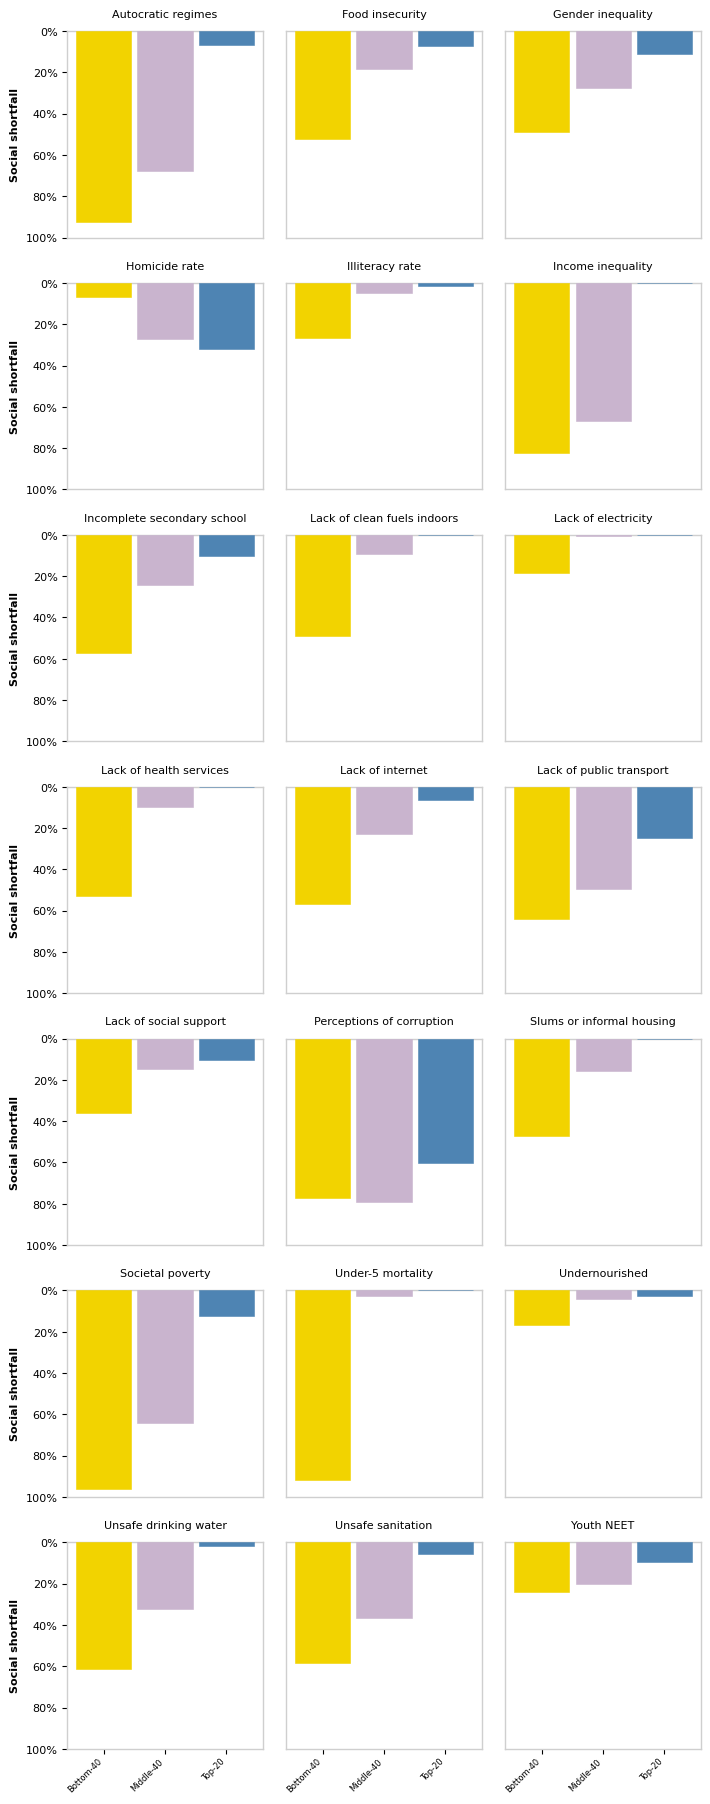

In [103]:
fig, axes = plt.subplots(7, 3, figsize=(7.2, 19.3), dpi=100)
axes = axes.flatten()

for i, ind in enumerate(panel_order):
    ax = axes[i]

    sub = (
        soc_plot.loc[soc_plot["indicator"] == ind]
        .set_index("group")
        .reindex(groups)
        .reset_index()
    )

    x = np.arange(len(groups))
    y = sub["value"].values
    bar_colors = [colors[g] for g in groups]

    ax.bar(
        x,
        y,
        color=bar_colors,
        edgecolor=bar_colors,
        linewidth=0.4,
        width=0.9,
        zorder=3
    )

    ax.set_title(title_map[ind], fontsize=8, pad=10, color="black")

    ax.set_ylim(0, 100)
    ax.invert_yaxis()
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: f"{int(v)}%"))

    if i % 3 == 0:
        ax.set_ylabel("Social shortfall", fontsize=8, weight="bold", color="black")
        ax.tick_params(axis="y", labelsize=8, colors="black", left=True, labelleft=True)
    else:
        ax.tick_params(axis="y", left=False, labelleft=False)

    ax.set_xticks(x)
    if i >= 18:
        ax.set_xticklabels(groups, rotation=45, ha="right", fontsize=6, color="black")
        ax.tick_params(axis="x", pad=2, colors="black")
    else:
        ax.set_xticklabels([])
        ax.tick_params(axis="x", length=0)

    ax.grid(False)
    ax.set_facecolor("white")

    for spine in ax.spines.values():
        spine.set_color("#cfcfcf")
        spine.set_linewidth(1)
        spine.set_zorder(1)

for j in range(len(panel_order), len(axes)):
    axes[j].axis("off")

plt.subplots_adjust(
    left=0.10,
    right=0.98,
    top=0.97,
    bottom=0.08,
    wspace=0.12,
    hspace=0.22
)

plt.show()

## Sandwich plot
Σε αυτό το στάδιο δημιουργείται το sandwich plot που είναι ένα συνδυαστικό διάγραμμα που αποτυπώνει ταυτόχρονα την οικολογική υπέρβαση (ecological overshoot) και την κοινωνική υστέρηση (social shortfall). Πιο συγκεκριμένα, το άνω τμήμα του διαγράμματος παρουσιάζει την οικολογική υπέρβαση σε σχέση με τα πλανητικά όρια και το κάτω τμήμα παρουσιάζει την κοινωνική υστέρηση. Για κάθε δείκτη φαίνεται η μεταβολή μεταξύ της αρχικής και τελικής χρονικής περιόδου. Οι ανοιχτόχρωμες κόκκινες μπάρες δείχνουν μείωση της υπέρβασης ή υστέρησης, ενώ οι σκουρόχρωμες κόκκινες μπάρες δείχνουν αύξηση της υπέρβασης ή υστέρησης.

#### Φόρτωση οικολογικών δεδομένων
Αρχικά, φορτώνονται τα παγκόσμια δεδομένα που σχετίζονται με την οικολογική διάσταση για τη περίοδο 2000-2022. Από τις εγγραφές κρατάμε μόνο αυτές που ανήκουν στο οικολογικό πεδίο (domain = ecological), τις οποίες θα παρουσιάσουμε στο άνω τμήμα του διαγράμματος. Έπειτα, η στήλη του overshoot (shortfallOvershoot_pct) μετατρέπεται σε αριθμητική μορφή και ορίζεται η σειρά εμφάνισης των δεικτών και οι τίτλοι με τους οποιούς θα παρουσιαστούν στο διάγραμμα.

In [104]:
eco_file = "data/a-fanning-doughnut-v3-a0460e5/Analysis-Final/myData/12_20250515_globalDoughnutData_2000-2022.csv"
eco_df = pd.read_csv(eco_file)

eco_df = eco_df.loc[eco_df["domain"] == "ecological"].copy()
eco_df["shortfallOvershoot_pct"] = pd.to_numeric(
    eco_df["shortfallOvershoot_pct"], errors="coerce"
)

eco_order = [
    "interhemAOD",
    "omega_a",
    "blueDev",
    "co2_ppm",
    "forestAreaMKM2",
    "chemicalsMt_Hzd",
    "hanppGtC",
    "nitrogenMt",
    "phosphorusMt",
    "erf_wm2",
    "soilDev",
    "extinction1900",
    "totalOzone"
]

eco_titles = {
    "interhemAOD": "Aerosol optical depth",
    "omega_a": "Aragonite saturation",
    "blueDev": "Blue-water flows",
    "co2_ppm": "CO2 concentration",
    "forestAreaMKM2": "Forest area",
    "chemicalsMt_Hzd": "Hazardous chemicals production",
    "hanppGtC": "Human appropriation of energy production",
    "nitrogenMt": "Nitrogen pollution",
    "phosphorusMt": "Phosphorus pollution",
    "erf_wm2": "Radiative forcing",
    "soilDev": "Soil moisture",
    "extinction1900": "Species extinctions",
    "totalOzone": "Stratospheric ozone concentration"
}

#### Βοηθητική συνάρτηση first_last_pct

Αυτή η βοηθητική συνάρτηση βρίσκει για κάθε δείκτη όλες τις διαθέσιμες παρατηρήσεις και διατηρεί μόνο τη πρώτη και τελευταία χρονικά διαθέσιμη τιμή.

In [105]:
def first_last_pct(data, indicators, value_col):
    rows = []
    for ind in indicators:
        g = data.loc[data["indicator"] == ind].sort_values("date").copy()
        g = g.dropna(subset=[value_col])
        if len(g) == 0:
            continue
        rows.append({
            "indicator": ind,
            "first_date": int(g.iloc[0]["date"]),
            "last_date": int(g.iloc[-1]["date"]),
            "first_pct": float(g.iloc[0][value_col]),
            "last_pct": float(g.iloc[-1][value_col])
        })
    return pd.DataFrame(rows)

eco_fl = first_last_pct(eco_df, eco_order, "shortfallOvershoot_pct")

#### Φόρτωση κοινωνικών δεδομένων
Στη συνέχεια φορτώνουμε και τα κοινωνικά δεδομένα που θα χρησιμοποιηθούν στο κάτω τμήμα του διαγράμματος. Αφού φορτωθούν τα αρχεία, εφαρμόζονται οι ίδιοι μετασχηματισμοί στα δεδομένα που είχαν χρησιμοποιηθεί και στις παραπάνω αναλύσεις των κοινωνικών δεικτών. Αφαιρούνται όσοι δείκτες δεν θα χρησιμοποιηθούν στην οπτικοποίηση και διατηρούνται μόνο τα δεδομένα που αφορούν το σύνολο του κόσμου (World). Έπειτα, ορίζεται η σειρά των δεικτών και οι τίτλοι με τους οποιούς θα παρουσιαστούν στο διάγραμμα και υπολογίζεται η πρώτη και η τελευταία χρονικά διαθέσιμη τιμή.

In [106]:
social_files = sorted([f for f in os.listdir(DATA_PATH) if f.startswith("soc-")])

soc = pd.concat(
    [pd.read_csv(DATA_PATH + f) for f in social_files],
    ignore_index=True
)

soc = soc.copy()

soc.loc[soc["indicator"].isin(["adultLiteracy", "secondarySchool"]), "value"] = (
    100 - soc.loc[soc["indicator"].isin(["adultLiteracy", "secondarySchool"]), "value"]
)
soc.loc[soc["indicator"].isin(["drinkingH2O", "sanitation"]), "value"] = (
    100 - soc.loc[soc["indicator"].isin(["drinkingH2O", "sanitation"]), "value"]
)
soc.loc[soc["indicator"].isin(["energyAccess", "energyIndoor"]), "value"] = (
    100 - soc.loc[soc["indicator"].isin(["energyAccess", "energyIndoor"]), "value"]
)
soc.loc[soc["indicator"].isin(["publicTrans", "internet"]), "value"] = (
    100 - soc.loc[soc["indicator"].isin(["publicTrans", "internet"]), "value"]
)
soc.loc[soc["indicator"] == "genderGapIndex", "value"] = (
    soc.loc[soc["indicator"] == "genderGapIndex", "value"] * 100
)
soc.loc[soc["indicator"] == "societalPoverty", "value"] = (
    soc.loc[soc["indicator"] == "societalPoverty", "value"] * 100
)
soc = soc.loc[~((soc["dimension"] == "housing") & (soc["indicator"] != "urbanSlums"))].copy()
soc = soc.loc[soc["indicator"] != "racialInequality"].copy()

soc["value"] = pd.to_numeric(soc["value"], errors="coerce")
soc = soc.dropna(subset=["value"]).copy()
soc_global = soc.loc[soc["group"] == "World"].copy()

soc_order = [
    "govRegimes",
    "under5death",
    "foodInsecurity",
    "genderGapIndex",
    "homicideOver5",
    "adultLiteracy",
    "urbanSlums",
    "palma",
    "secondarySchool",
    "energyIndoor",
    "energyAccess",
    "UHCindex",
    "internet",
    "publicTrans",
    "socialSupport",
    "controlCorruption",
    "societalPoverty",
    "undernourishment",
    "drinkingH2O",
    "sanitation",
    "youthNEET"
]

soc_titles = {
    "govRegimes": "Autocratic regimes",
    "under5death": "Child mortality",
    "foodInsecurity": "Food insecurity",
    "genderGapIndex": "Gender inequality",
    "homicideOver5": "Homicides",
    "adultLiteracy": "Illiteracy",
    "urbanSlums": "Inadequate housing",
    "palma": "Income inequality",
    "secondarySchool": "Incomplete secondary school",
    "energyIndoor": "Lack of clean fuels indoors",
    "energyAccess": "Lack of electricity",
    "UHCindex": "Lack of health services",
    "internet": "Lack of internet",
    "publicTrans": "Lack of public transport",
    "socialSupport": "Lack of social support",
    "controlCorruption": "Perceptions of corruption",
    "societalPoverty": "Societal poverty",
    "undernourishment": "Undernourished",
    "drinkingH2O": "Unsafe drinking water",
    "sanitation": "Unsafe sanitation",
    "youthNEET": "Youth unemployment"
}

soc_fl = first_last_pct(soc_global, soc_order, "value")

#### Υπολογισμός βασικού επιπέδου και μεταβολής

Για κάθε δείκτη, και στο άνω και στο κάτω μέρος του διαγράμματος, υπολογίζεται το βασικό επίπεδο το οποίο αντιστοιχεί στη μικρότερη τιμή από τη πρώτη και τελευταία χρονιά. Αυτή η τιμή δηλαδή λειτουργεί ως βάση, καθώς υπάρχει και στις δύο χρονικές στιγμές. Έπειτα, υπολογίζεται η απόλυτη διαφορά μεταξύ των δύο τιμών (αρχικής και τελικής), η οποία αντιστοιχεί στη μεταβολή του κάθε δείκτη μέσα στο χρόνο (αύξηση ή μείωση). Για το άνω μέρος του διαγράμματος εφαρμόζεται περιορισμός της κλίμακας στο 300%, ώστε το διάγραμμα να παραμείνει ευανάγνωστο και να μην αλλοιώνεται η οπτική σύγκριση μεταξύ των δεικτών από τυχόν ακραίες τιμές.

In [107]:
eco_fl["base_pct"] = np.minimum(eco_fl["first_pct"], eco_fl["last_pct"])
eco_fl["diff_pct"] = np.abs(eco_fl["last_pct"] - eco_fl["first_pct"])

eco_fl["base_plot"] = eco_fl["base_pct"].clip(upper=300)
eco_fl["diff_plot"] = np.minimum(eco_fl["diff_pct"], 300 - eco_fl["base_plot"])

soc_fl["base_pct"] = np.minimum(soc_fl["first_pct"], soc_fl["last_pct"])
soc_fl["diff_pct"] = np.abs(soc_fl["last_pct"] - soc_fl["first_pct"])

#### Ορισμός χρωμάτων μεταβολής

Στο σημείο αυτό ορίζονται τα χρώματα που χρησιμοποιούνται για την οπτική κωδικοποίηση του sandwich plot. Για κάθε τμήμα του διαγράμματος υπάρχει ένα σταθερό χρώμα βάσης το οποίο χρησιμοποιείται για το κοινό βασικό επίπεδο του δείκτη.
Επιπλέον, ορίζονται δύο διαφορετικά χρώματα για το τμήμα της μεταβολής. Το ανοιχτό κόκκινο χρησιμοποιείται όταν η τελική τιμή είναι μικρότερη από την αρχική, δηλαδή όταν παρατηρείται μείωση της υστέρησης ή της υπέρβασης. Αντίθετα, το σκούρο κόκκινο χρησιμοποιείται όταν η τελική τιμή είναι μεγαλύτερη από την αρχική, δηλαδή όταν παρατηρείται αύξηση του προβλήματος. Η χρωματική αυτή κωδικοποίηση εφαρμόζεται τόσο στους οικολογικούς όσο και στους κοινωνικούς δείκτες, ώστε η κατεύθυνση της μεταβολής να γίνεται άμεσα αντιληπτή.

In [108]:
eco_base_color = "#D11C45"
eco_light_red = "#E57C93"
eco_dark_red = "#B44E4B"

soc_base_color = "darkred"
soc_light_red = "#E15A78"
soc_dark_red = "#B44E4B"

eco_diff_colors = [
    eco_dark_red if last > first else eco_light_red
    for first, last in zip(eco_fl["first_pct"], eco_fl["last_pct"])
]
soc_diff_colors = [
    soc_dark_red if last > first else soc_light_red
    for first, last in zip(soc_fl["first_pct"], soc_fl["last_pct"])
]

#### Δημιουργία και μορφοποίηση του διαγράμματος

Τέλος, δημιουργείται το τελικό sandwich plot που αποτελείται από δύο κατακόρυφα τοποθετημένα τμήματα. Και στα δύο τμήματα κάθε δείκτης απεικονίζεται μέσω στοίβαξης του βασικού επιπέδου και της μεταβολής. Στο οικολογικό panel οι μπάρες εκτείνονται προς τα πάνω, ενώ στο κοινωνικό panel ο κατακόρυφος άξονας αντιστρέφεται, ώστε οι τιμές του shortfall να κατευθύνονται οπτικά προς τα κάτω. Επιπλέον, ρυθμίζονται οι τίτλοι των δεικτών, οι άξονες, τα περιθώρια και οι αποστάσεις μεταξύ των δύο τμημάτων, ώστε το τελικό αποτέλεσμα να είναι ευανάγνωστο.

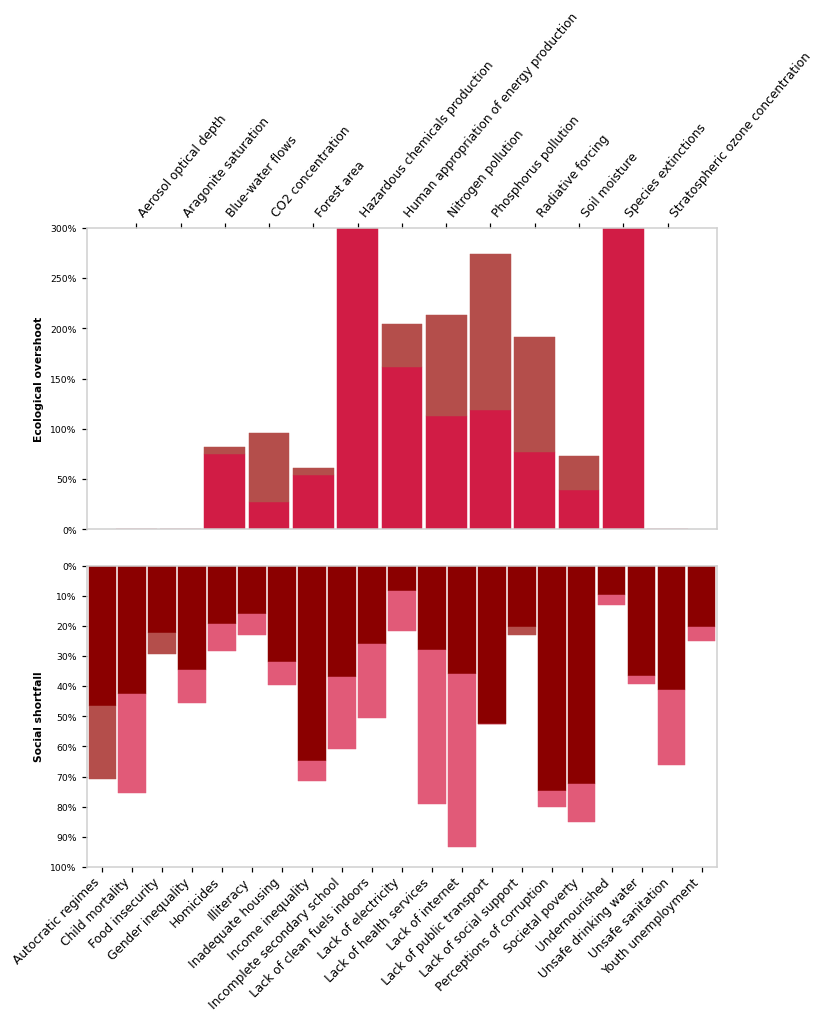

In [109]:
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(6.5, 7.0),
    dpi=110,
    gridspec_kw={"height_ratios": [1, 1]}
)
x1 = np.arange(len(eco_fl))

ax1.bar(
    x1,
    eco_fl["base_plot"],
    color=eco_base_color,
    edgecolor=eco_base_color,
    width=0.92,
    linewidth=0.3
)

ax1.bar(
    x1,
    eco_fl["diff_plot"],
    bottom=eco_fl["base_plot"],
    color=eco_diff_colors,
    edgecolor=eco_diff_colors,
    width=0.92,
    linewidth=0.3
)

ax1.set_ylim(0, 300)
ax1.set_ylabel("Ecological overshoot", fontsize=7, weight="bold", color="black")
ax1.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: f"{int(v)}%"))

ax1.set_xticks(x1)
ax1.set_xticklabels(
    [eco_titles[i] for i in eco_fl["indicator"]],
    rotation=50,
    ha="left",
    fontsize=8,
    color="black"
)
ax1.xaxis.tick_top()
ax1.tick_params(axis="x", pad=2, colors="black")
ax1.tick_params(axis="y", labelsize=6, colors="black")

ax1.grid(False)
ax1.set_facecolor("white")

for spine in ax1.spines.values():
    spine.set_color("#d0d0d0")
    spine.set_linewidth(1)

x2 = np.arange(len(soc_fl))

ax2.bar(
    x2,
    soc_fl["base_pct"],
    color=soc_base_color,
    edgecolor=soc_base_color,
    width=0.92,
    linewidth=0.3
)

ax2.bar(
    x2,
    soc_fl["diff_pct"],
    bottom=soc_fl["base_pct"],
    color=soc_diff_colors,
    edgecolor=soc_diff_colors,
    width=0.92,
    linewidth=0.3
)

ax2.set_xlim(-0.5, len(soc_fl) - 0.5)

ax2.set_ylim(0, 100)
ax2.invert_yaxis()
ax2.set_yticks(np.arange(0, 101, 10))
ax2.set_ylabel("Social shortfall", fontsize=7, weight="bold", color="black")
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: f"{int(v)}%"))

ax2.set_xticks(x2)
ax2.set_xticklabels(
    [soc_titles[i] for i in soc_fl["indicator"]],
    rotation=45,
    ha="right",
    fontsize=8,
    color="black"
)
ax2.tick_params(axis="x", pad=2, colors="black")
ax2.tick_params(axis="y", labelsize=6, colors="black")

ax2.grid(False)
ax2.set_facecolor("white")

for spine in ax2.spines.values():
    spine.set_color("#d0d0d0")
    spine.set_linewidth(1)

plt.subplots_adjust(
    left=0.10,
    right=0.98,
    top=0.93,
    bottom=0.10,
    hspace=0.12
)

plt.show()

## Doughnut Plot

Στο τελικό στάδιο της εργασίας δημιουργείται το διάγραμμα Doughnut Plot που συνοψίζει οπτικά τη θέση της ανθρωπότητας σε σχέση τόσο με την κοινωνική θεμελίωση (social foundation) όσο και με το οικολογικό ταβάνι (ecological ceiling). Το εσωτερικό τμήμα του διαγράμματος αποτυπώνει την κοινωνική υστέρηση, ενώ το εξωτερικό τμήμα αποτυπώνει την οικολογική υπέρβαση σε σχέση με τα πλανητικά όρια. Σε αντίθεση με την αρχική εκδοχή του διαγράμματος των συγγραφέων, οι τιμές είναι ανάλογες με το εμβαδό κάθε σφήνας και όχι με το μήκος της. Με αυτόν τον τρόπο, οι διαφορές μεταξύ των δεικτών αποδίδονται πιο πιστά και πιο ισορροπημένα. Επιπλέον, για τις εξωτερικές οικολογικές σφήνες εφαρμόζεται κατάλληλη κλιμάκωση, ώστε οι πολύ υψηλές τιμές υπέρβασης να χωρούν στο χώρο χωρίς να αλλοιώνεται η συνολική μορφή του διαγράμματος. Το τελικό αποτέλεσμα είναι διαδραστικό, δηλαδή ο χρήστης μπορεί να εξερευνήσει τη τιμή κάθε δείκτη μέσω hover.

#### Φόρτωση δεδομένων 
Αρχικά, φορτώνονται τα επεξεργασμένα δεδομένα που θα χρησιμοποιηθούν για τη δημιουργία του doughnut plot. Από το σύνολο δεδομένων διατηρούνται μόνο οι εγγραφές που αφορούν το παγκόσμιο doughnut και το σύνολο του κόσμου (World), ώστε η οπτικοποίηση να αποτυπώνει τη συνολική παγκόσμια εικόνα. Η μεταβλητή "ratio" μετατρέπεται σε αριθμητική μορφή και απομακρύνονται ελλιπείς τιμές, αν υπάρχουν. Για κάθε δείκτη διατηρείται μόνο η τελευταία διαθέσιμη χρονική παρατήρηση, ώστε το τελικό διάγραμμα να παρουσιάζει την πιο πρόσφατη κατάσταση για κάθε κοινωνικό και οικολογικό μέγεθος.

In [110]:
DATA_FILE = "data/a-fanning-doughnut-v3-a0460e5/Analysis-Final/myData/5_20250108_doughnutDat-boundariesRatios.csv"
df = pd.read_csv(DATA_FILE)

df = df.loc[
    (df["type"] == "global doughnut") &
    (df["group"] == "World")
].copy()

df["ratio"] = pd.to_numeric(df["ratio"], errors="coerce")
df = df.dropna(subset=["ratio"]).copy()

df_latest = (
    df.sort_values(["indicator", "date"])
      .groupby("indicator", as_index=False)
      .tail(1)
      .reset_index(drop=True)
)

#### Ορισμός δεικτών και συναρτήσεων
Εδώ ορίζονται οι κοινωνικοί και οι οικολογικοί δείκτες που θα εμφανιστούν στο doughnut plot, καθώς και η σειρά των ομάδων στις οποίες ανήκουν.

Έπειτα, ορίζονται βοηθητικές συναρτήσεις που χρησιμοποιούνται για την ανάκτηση των τιμών των δεικτών, τη μετατροπή των λόγων σε ποσοστά κοινωνικής υστέρησης ή οικολογικής υπέρβασης, καθώς και για γεωμετρικούς υπολογισμούς που είναι απαραίτητοι για την τοποθέτηση κειμένου και hover περιοχών στο πολικό διάγραμμα.

In [111]:
eco_items = [
    ("totalOzone",       "ozone depletion",        "Stratospheric ozone concentration"),
    ("extinction1900",   "biodiversity breakdown", "Species extinctions"),
    ("hanppGtC",         "biodiversity breakdown", "Human appropriation of energy produced by plants"),
    ("forestAreaMKM2",   "land conversion",        "Forest area"),
    ("blueDev",          "freshwater disruption",  "Blue-water flows"),
    ("soilDev",          "freshwater disruption",  "Soil moisture"),
    ("interhemAOD",      "air pollution",          "Aerosol optical depth"),
    ("phosphorusMt",     "nutrient pollution",     "Phosphorus pollution"),
    ("nitrogenMt",       "nutrient pollution",     "Nitrogen pollution"),
    ("chemicalsMt_Hzd",  "chemical pollution",     "Hazardous chemicals production"),
    ("omega_a",          "ocean acidification",    "Aragonite saturation"),
    ("co2_ppm",          "climate change",         "CO2 concentration"),
    ("erf_wm2",          "climate change",         "Radiative forcing"),
]

soc_items = [
    ("drinkingH2O",       "water",           "Unsafe drinking water"),
    ("sanitation",        "water",           "Unsafe sanitation"),
    ("energyAccess",      "energy",          "Lack of electricity"),
    ("energyIndoor",      "energy",          "Lack of clean fuels indoors"),
    ("internet",          "connectivity",    "Lack of internet"),
    ("publicTrans",       "connectivity",    "Lack of public transport"),
    ("urbanSlums",        "housing",         "Inadequate housing"),
    ("genderGapIndex",    "equality",        "Gender inequality"),
    ("socialSupport",     "social cohesion", "Lack of social support"),
    ("palma",             "social cohesion", "Income inequality"),
    ("govRegimes",        "political voice", "Autocratic regimes"),
    ("controlCorruption", "peace & justice", "Perceptions of corruption"),
    ("homicideOver5",     "peace & justice", "Homicides"),
    ("societalPoverty",   "income & work",   "Societal poverty"),
    ("youthNEET",         "income & work",   "Youth unemployment"),
    ("adultLiteracy",     "education",       "Illiteracy"),
    ("secondarySchool",   "education",       "Incomplete secondary school"),
    ("under5death",       "health",          "Child mortality"),
    ("UHCindex",          "health",          "Lack of health services"),
    ("foodInsecurity",    "food",            "Food insecurity"),
]

soc_group_order = [
    "water", "energy", "connectivity", "housing", "equality",
    "social cohesion", "political voice", "peace & justice",
    "income & work", "education", "health", "food",
]

eco_group_order = [
    "ozone depletion", "biodiversity breakdown", "land conversion",
    "freshwater disruption", "air pollution", "nutrient pollution",
    "chemical pollution", "ocean acidification", "climate change",
]

POLAR_ROTATION = 90
POLAR_DIRECTION = "counterclockwise"

def get_ratio(indicator):
    row = df_latest.loc[df_latest["indicator"] == indicator]
    if row.empty:
        return np.nan
    return float(row["ratio"].iloc[0])

def eco_pct_from_ratio(r):
    return max(0.0, (r - 1.0) * 100.0)

def soc_pct_from_ratio(r):
    return min(100.0, max(0.0, (1.0 - r) * 100.0))

def hex_to_rgb(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i+2], 16) for i in (0, 2, 4))

def interp_color(c1, c2, t):
    r1, g1, b1 = hex_to_rgb(c1)
    r2, g2, b2 = hex_to_rgb(c2)
    return "#{:02x}{:02x}{:02x}".format(
        int(r1 + (r2 - r1) * t),
        int(g1 + (g2 - g1) * t),
        int(b1 + (b2 - b1) * t)
    )

def plot_theta_to_math(theta_deg):
    if POLAR_DIRECTION == "clockwise":
        return POLAR_ROTATION - theta_deg
    return POLAR_ROTATION + theta_deg

def polar_to_paper(theta_deg, r, rmax):
    theta_math = math.radians(plot_theta_to_math(theta_deg))
    rr = r / rmax
    x = 0.5 + 0.5 * rr * math.cos(theta_math)
    y = 0.5 + 0.5 * rr * math.sin(theta_math)
    return x, y

def build_hover_cloud(df_plot, n_r=12, n_theta=5, theta_fill_ratio=0.72):
    rv, tv, labels, pcts = [], [], [], []
    for _, row in df_plot.iterrows():
        rs, re = float(row["base"]), float(row["base"] + row["r"])
        pad = (re - rs) * 0.08 if re > rs else 0.0

        rr_start = rs + pad
        rr_end = max(rs + pad, re - pad)

        for th in np.linspace(
            row["theta"] - row["width"] * theta_fill_ratio / 2,
            row["theta"] + row["width"] * theta_fill_ratio / 2,
            n_theta
        ):
            for rr in np.linspace(rr_start, rr_end, n_r):
                rv.append(rr)
                tv.append(th)
                labels.append(row["label"])
                pcts.append(row["pct"])
    return rv, tv, np.stack([labels, pcts], axis=-1)

def band_text_angle(theta_deg):
    ang = plot_theta_to_math(theta_deg) - 90

    while ang > 90:
        ang -= 180
    while ang < -90:
        ang += 180

    ang = max(10, min(-10, ang))
    return ang - 5

#### Κατασκευή των πινάκων
Στο στάδιο αυτό δημιουργούνται δύο επιμέρους πίνακες δεδομένων (ένας για τους οικολογικούς δείκτες και ένας για τους κοινωνικούς δείκτες). Για κάθε δείκτη ανακτάται η τελευταία διαθέσιμη τιμή του λόγου (ratio) και μετατρέπεται σε κατάλληλο ποσοστό, ανάλογα με το αν πρόκειται για οικολογική υπέρβαση ή κοινωνική υστέρηση.
Για τους οικολογικούς δείκτες υπολογίζεται το ποσοστό υπέρβασης σε σχέση με το πλανητικό όριο, ενώ για τους κοινωνικούς δείκτες υπολογίζεται το ποσοστό μη κάλυψης της αντίστοιχης ανάγκης. 

In [112]:
eco_plot = pd.DataFrame([
    {
        "indicator": ind,
        "dimension": dim,
        "label": label,
        "ratio": get_ratio(ind),
        "pct": eco_pct_from_ratio(get_ratio(ind)) if pd.notna(get_ratio(ind)) else 0.0
    }
    for ind, dim, label in eco_items
])

soc_plot = pd.DataFrame([
    {
        "indicator": ind,
        "dimension": dim,
        "label": label,
        "ratio": get_ratio(ind),
        "pct": soc_pct_from_ratio(get_ratio(ind)) if pd.notna(get_ratio(ind)) else 0.0
    }
    for ind, dim, label in soc_items
])

#### Υπολογισμός γεωμετρίας
Στο σημείο αυτό ορίζεται η γεωμετρία του σχήματος, δηλαδή οι ακτίνες των επιμέρους δακτυλίων και ο τρόπος με τον οποίο οι τιμές μετατρέπονται σε μήκη σφηνών. Όπως αναφέρθηκε και νωρίτερα, η τιμή κάθε δείκτη είναι ανάλογη με το εμβαδό της σφήνας και όχι απλώς με το μήκος της. Για τον λόγο αυτό χρησιμοποιούνται τετραγωνικές ρίζες στους υπολογισμούς των ακτίνων. Παράλληλα, ορίζονται οι γωνίες και τα πλάτη των σφηνών, τόσο για τους οικολογικούς όσο και για τους κοινωνικούς δείκτες, με βάση τη θεματική ομάδα στην οποία ανήκουν. Εισάγονται επίσης μικρά κενά μεταξύ των ομάδων, ώστε το τελικό διάγραμμα να είναι πιο ευανάγνωστο και να διαφοροποιούνται μεταξύ τους οι διαστάσεις.

In [113]:
hole_r = 0.18
soc_outer_r = 0.58

social_foundation_base = soc_outer_r
social_foundation_thickness = 0.04
light_green_base = social_foundation_base + social_foundation_thickness
light_green_thickness = 0.11
ecological_ceiling_base = light_green_base + light_green_thickness
ecological_ceiling_thickness = 0.04
eco_base_r = ecological_ceiling_base + ecological_ceiling_thickness
eco_scale = 0.0048
rmax = 1.75

soc_scale = (soc_outer_r**2 - hole_r**2) / 100.0
soc_plot["inner_r"] = np.sqrt(np.maximum(hole_r**2, soc_outer_r**2 - soc_scale * soc_plot["pct"]))
soc_plot["base"] = soc_plot["inner_r"]
soc_plot["r"] = soc_outer_r - soc_plot["inner_r"]

eco_plot["outer_r"] = np.sqrt(eco_base_r**2 + eco_scale * eco_plot["pct"])
eco_plot["base"] = eco_base_r
eco_plot["r"] = eco_plot["outer_r"] - eco_base_r

eco_group_gap = 4.0
eco_group_span = 360.0 / len(eco_group_order) - eco_group_gap

for i, dim in enumerate(eco_group_order):
    idx = eco_plot.index[eco_plot["dimension"] == dim].tolist()
    k = len(idx)
    gc = i * 360.0 / len(eco_group_order)

    if k == 1:
        eco_plot.loc[idx[0], "theta"] = gc
        eco_plot.loc[idx[0], "width"] = eco_group_span
    else:
        edges = np.linspace(gc - eco_group_span / 2, gc + eco_group_span / 2, k + 1)
        for j, ix in enumerate(idx):
            eco_plot.loc[ix, "theta"] = (edges[j] + edges[j + 1]) / 2
            eco_plot.loc[ix, "width"] = edges[j + 1] - edges[j]

soc_group_gap = 2.0
soc_group_span = 360.0 / len(soc_group_order) - soc_group_gap

for i, dim in enumerate(soc_group_order):
    idx = soc_plot.index[soc_plot["dimension"] == dim].tolist()
    k = len(idx)
    gc = i * 360.0 / len(soc_group_order)

    if k == 1:
        soc_plot.loc[idx[0], "theta"] = gc
        soc_plot.loc[idx[0], "width"] = soc_group_span
    else:
        edges = np.linspace(gc - soc_group_span / 2, gc + soc_group_span / 2, k + 1)
        for j, ix in enumerate(idx):
            soc_plot.loc[ix, "theta"] = (edges[j] + edges[j + 1]) / 2
            soc_plot.loc[ix, "width"] = edges[j + 1] - edges[j]

#### Χρωματισμός διαγράμματος
Παρακάτω ορίζονται τα χρώματα που χρησιμοποιούνται στο doughnut plot. Οι κοινωνικές και οικολογικές σφήνες χρωματίζονται με διαβαθμίσεις που εξαρτώνται από το μέγεθος της αντίστοιχης τιμής και έτσι οι μεγαλύτερες υπερβάσεις ή υστερήσεις παρουσιάζονται με πιο έντονο χρώμα. Επίσης, ορίζονται τα σταθερά χρώματα των δακτυλίων που αντιστοιχούν στις ζώνες της κοινωνικής θεμελίωσης και του οικολογικού ταβανιού.

Στη συνέχεια δημιουργείται το κύριο διαδραστικό σχήμα, στο οποίο προστίθενται οι εσωτερικοί δακτύλιοι, οι οικολογικές σφήνες, οι κοινωνικές σφήνες και οι αόρατες περιοχές hover. Οι περιοχές αυτές επιτρέπουν την εμφάνιση της τιμής κάθε δείκτη κατά την αλληλεπίδραση του χρήστη, χωρίς να επιβαρύνουν οπτικά το συνολικό αποτέλεσμα.

In [114]:
eco_max = eco_plot["pct"].max()
soc_max = soc_plot["pct"].max()

eco_plot["color"] = [
    interp_color("#ebb0b7", "#7b1f58", p / eco_max if eco_max > 0 else 0)
    for p in eco_plot["pct"]
]
soc_plot["color"] = [
    interp_color("#e08a98", "#7b1f58", p / soc_max if soc_max > 0 else 0)
    for p in soc_plot["pct"]
]

ring_dark = "#1e7b43"
ring_light = "#74b943"
center_fill = "#efe8e4"

fig = go.Figure()

fig.add_trace(go.Barpolar(
    r=[hole_r], theta=[0], width=[360], base=[0],
    marker_color=center_fill, marker_line_color=center_fill,
    hoverinfo="skip", showlegend=False
))
fig.add_trace(go.Barpolar(
    r=[social_foundation_thickness], theta=[0], width=[360],
    base=[social_foundation_base],
    marker_color=ring_dark, marker_line_color=ring_dark,
    hoverinfo="skip", showlegend=False
))
fig.add_trace(go.Barpolar(
    r=[light_green_thickness], theta=[0], width=[360],
    base=[light_green_base],
    marker_color=ring_light, marker_line_color=ring_light,
    hoverinfo="skip", showlegend=False
))
fig.add_trace(go.Barpolar(
    r=[ecological_ceiling_thickness], theta=[0], width=[360],
    base=[ecological_ceiling_base],
    marker_color=ring_dark, marker_line_color=ring_dark,
    hoverinfo="skip", showlegend=False
))
fig.add_trace(go.Barpolar(
    r=eco_plot["r"], theta=eco_plot["theta"], width=eco_plot["width"],
    base=eco_plot["base"], marker_color=eco_plot["color"],
    marker_line_color=eco_plot["color"], hoverinfo="skip", showlegend=False
))
erh, eth, ecd = build_hover_cloud(eco_plot, n_r=18, n_theta=5, theta_fill_ratio=0.78)
fig.add_trace(go.Scatterpolar(
    r=erh, theta=eth, mode="markers",
    marker=dict(size=10, color="rgba(0,0,0,0)"),
    customdata=ecd,
    hovertemplate="%{customdata[0]}: %{customdata[1]:.2f}%<extra></extra>",
    showlegend=False
))
fig.add_trace(go.Barpolar(
    r=soc_plot["r"], theta=soc_plot["theta"], width=soc_plot["width"],
    base=soc_plot["base"], marker_color=soc_plot["color"],
    marker_line_color=soc_plot["color"], hoverinfo="skip", showlegend=False
))
srh, sth, scd = build_hover_cloud(soc_plot, n_r=14, n_theta=5, theta_fill_ratio=0.78)
fig.add_trace(go.Scatterpolar(
    r=srh, theta=sth, mode="markers",
    marker=dict(size=10, color="rgba(0,0,0,0)"),
    customdata=scd,
    hovertemplate="%{customdata[0]}: %{customdata[1]:.2f}%<extra></extra>",
    showlegend=False
))
None

#### Εξαγωγή του τελικού διαγράμματος σε HTML με JavaScript
Τέλος, προσθέτουμε τους τίτλους των βασικών δακτυλίων και υπολογίζουμε τα στοιχεία που χρειάζονται για να τοποθετηθούν σωστά οι εξωτερικοί και οι ενδιάμεσοι τίτλοι. Επειδή το Plotly δεν δίνει από μόνο του αρκετή ευελιξία για την τοποθέτηση όλων των κειμένων κυκλικά, χρησιμοποιούμε επιπλέον JavaScript μετά την εξαγωγή του γραφήματος σε HTML.
Έτσι τοποθετούνται δυναμικά οι τίτλοι πάνω στο διάγραμμα, με σκοπό να έχουν σωστό προσανατολισμό και να διαβάζονται εύκολα. Στο τέλος, το διάγραμμα αποθηκεύεται σε αρχείο HTML και μπορεί να ανοίξει στον browser.

In [115]:
annotations = []

sf_theta_positions = np.linspace(30, -30, 17)
sf_text = list("SOCIAL FOUNDATION")
sf_r = social_foundation_base + social_foundation_thickness * 0.50

for ch, th in zip(sf_text, sf_theta_positions):
    x, y = polar_to_paper(th, sf_r, rmax)
    annotations.append(dict(
        x=x, y=y,
        xref="paper", yref="paper",
        text=f"<b>{ch}</b>",
        showarrow=False,
        textangle=band_text_angle(th),
        font=dict(size=9, color="white", family="Arial"),
        xanchor="center",
        yanchor="middle"
    ))

ec_theta_positions = np.linspace(35, -35, 18)
ec_text = list("ECOLOGICAL CEILING")
ec_r = ecological_ceiling_base + ecological_ceiling_thickness * 0.50

for ch, th in zip(ec_text, ec_theta_positions):
    x, y = polar_to_paper(th, ec_r, rmax)
    annotations.append(dict(
        x=x, y=y,
        xref="paper", yref="paper",
        text=f"<b>{ch}</b>",
        showarrow=False,
        textangle=band_text_angle(th),
        font=dict(size=9, color="white", family="Arial"),
        xanchor="center",
        yanchor="middle"
    ))

fig.update_layout(
    width=950,
    height=950,
    margin=dict(l=20, r=20, t=20, b=20),
    paper_bgcolor="white",
    hovermode="closest",
    annotations=annotations,
    polar=dict(
        bgcolor="white",
        radialaxis=dict(visible=False, range=[0, rmax]),
        angularaxis=dict(
            visible=False,
            rotation=POLAR_ROTATION,
            direction=POLAR_DIRECTION
        )
    )
)

eco_group_display = {
    "ozone depletion":        "ozone depletion",
    "biodiversity breakdown": "biodiversity breakdown",
    "land conversion":        "land conversion",
    "freshwater disruption":  "freshwater disruption",
    "air pollution":          "air pollution",
    "nutrient pollution":     "nutrient pollution",
    "chemical pollution":     "chemical pollution",
    "ocean acidification":    "ocean acidification",
    "climate change":         "climate change",
}

eco_label_data = []
for dim in eco_group_order:
    grp = eco_plot.loc[eco_plot["dimension"] == dim]
    if grp.empty:
        continue
    ang = np.deg2rad(grp["theta"].to_numpy())
    mt = np.rad2deg(np.arctan2(np.mean(np.sin(ang)), np.mean(np.cos(ang))))
    if mt < 0:
        mt += 360
    eco_label_data.append((mt, eco_group_display[dim], eco_base_r + 0.10))

soc_label_data = []
mid_r = light_green_base + light_green_thickness * 0.50
for dim in soc_group_order:
    rows = soc_plot[soc_plot["dimension"] == dim]
    if rows.empty:
        continue
    ang = np.deg2rad(rows["theta"].to_numpy())
    mt = np.rad2deg(np.arctan2(np.mean(np.sin(ang)), np.mean(np.cos(ang))))
    if mt < 0:
        mt += 360
    soc_label_data.append((mt, dim, mid_r))

def to_js_arr(data):
    parts = []
    for theta, text, r in data:
        safe = text.replace('"', '\\"')
        parts.append(
            '{theta:' + f'{theta:.4f}' +
            ', r:' + f'{r:.4f}' +
            ', text:"' + safe + '"}'
        )
    return '[' + ', '.join(parts) + ']'

html_str = fig.to_html(full_html=True, include_plotlyjs="cdn")

JS_CODE = """
<script>
(function() {
  var ROTATION  = """ + str(POLAR_ROTATION) + """;
  var DIRECTION = \"""" + POLAR_DIRECTION + """\";
  var RMAX      = """ + str(rmax) + """;

  var ecoLabels = """ + to_js_arr(eco_label_data) + """;
  var socLabels = """ + to_js_arr(soc_label_data) + """;

  function plotlyToMath(theta) {
    return (DIRECTION === "clockwise") ? ROTATION - theta : ROTATION + theta;
  }

  function tangentAngle(theta) {
    var m = plotlyToMath(theta);
    var a = -(m + 90);
    a = ((a % 360) + 360) % 360;
    if (a > 180) a -= 360;
    if (a > 180) a -= 360;
    if (a >  90) a -= 180;
    if (a < -90) a += 180;
    return a;
  }

  function getPolarBB(gd) {
    try {
      var fl = gd._fullLayout;
      var polar = fl.polar;
      var domain = polar.domain;
      var W = fl.width;
      var H = fl.height;
      var margin = fl.margin;
      var plotW = W - margin.l - margin.r;
      var plotH = H - margin.t - margin.b;
      var x0 = margin.l + domain.x[0] * plotW;
      var x1 = margin.l + domain.x[1] * plotW;
      var y0 = margin.t + (1 - domain.y[1]) * plotH;
      var y1 = margin.t + (1 - domain.y[0]) * plotH;
      var cx = (x0 + x1) / 2;
      var cy = (y0 + y1) / 2;
      var radius = Math.min(x1 - x0, y1 - y0) / 2;
      return {cx: cx, cy: cy, radius: radius};
    } catch(e) {
      return null;
    }
  }

  function toSVG(theta, r, bb) {
    var math_rad = Math.PI / 180 * plotlyToMath(theta);
    var frac = r / RMAX;
    return {
      x: bb.cx + frac * bb.radius * Math.cos(math_rad),
      y: bb.cy - frac * bb.radius * Math.sin(math_rad)
    };
  }

  function svgText(svg, x, y, lines, fontSize, color, rotAngle) {
    var g = document.createElementNS("http://www.w3.org/2000/svg", "g");
    g.setAttribute("class", "doughnut-label");
    g.setAttribute(
      "transform",
      "translate(" + x.toFixed(1) + "," + y.toFixed(1) + ") rotate(" + rotAngle.toFixed(1) + ")"
    );

    var lh = fontSize * 1.25;
    var y0 = -(lines.length - 1) * lh / 2;

    lines.forEach(function(line, i) {
      var t = document.createElementNS("http://www.w3.org/2000/svg", "text");
      t.setAttribute("x", "0");
      t.setAttribute("y", (y0 + i * lh).toFixed(1));
      t.setAttribute("text-anchor", "middle");
      t.setAttribute("dominant-baseline", "middle");
      t.setAttribute("font-size", fontSize + "px");
      t.setAttribute("font-family", "Arial, sans-serif");
      t.setAttribute("fill", color);
      t.textContent = line;
      g.appendChild(t);
    });

    svg.appendChild(g);
    return g;
  }

  function draw() {
    var gd = document.querySelector('.plotly-graph-div');
    if (!gd || !gd._fullLayout) { setTimeout(draw, 100); return; }

    var svg = gd.querySelector('svg.main-svg');
    if (!svg) { setTimeout(draw, 100); return; }

    var bb = getPolarBB(gd);
    if (!bb || bb.radius < 5) { setTimeout(draw, 100); return; }

    svg.querySelectorAll('.doughnut-label').forEach(function(el) {
      el.parentNode.removeChild(el);
    });

    var g = document.createElementNS("http://www.w3.org/2000/svg", "g");
    g.setAttribute("class", "doughnut-label");
    svg.appendChild(g);

    ecoLabels.forEach(function(d) {
      var pos = toSVG(d.theta, d.r, bb);
      var words = d.text.split(" ");
      var lines;
      if (words.length <= 1) {
        lines = words;
      } else {
        var mid = Math.ceil(words.length / 2);
        lines = [words.slice(0, mid).join(" "), words.slice(mid).join(" ")];
      }
      svgText(g, pos.x, pos.y, lines, 11, "#222222", tangentAngle(d.theta));
    });

    socLabels.forEach(function(d) {
      var pos = toSVG(d.theta, d.r, bb);
      svgText(g, pos.x, pos.y, [d.text], 10, "white", tangentAngle(d.theta));
    });
  }

  function waitAndDraw() {
    var gd = document.querySelector('.plotly-graph-div');
    if (!gd) { setTimeout(waitAndDraw, 100); return; }

    gd.addEventListener('plotly_afterplot', function() {
      setTimeout(draw, 50);
    });

    setTimeout(draw, 300);
  }

  if (document.readyState === 'complete') {
    waitAndDraw();
  } else {
    window.addEventListener('load', waitAndDraw);
  }
})();
</script>
"""

html_out = html_str.replace("</body>", JS_CODE + "\n</body>")

with open("doughnut-plot.html", "w", encoding="utf-8") as f:
    f.write(html_out)

print("Saved → doughnut-plot.html")

Saved → doughnut-plot.html


## Συμπεράσματα

Η παρούσα εργασία εξέτασε τη διαχρονικη εξέλιξη των δεικτών που αφορούν τόσο την κοινωνική θεμελίωση όσο και το οικολογικό ταβάνι για την περίοδο 2000–2022, με στόχο την παρατήρηση της κοινωνικής προόδου και της περιβαλλοντικής βιωσιμότητας σε παγκόσμιο επίπεδο.

Από την ανάλυση των κοινωνικών δεικτών προκύπτει μια θετική εικόνα, καθώς σε αρκετούς τομείς παρατηρείται βελτίωση, όπως η εκπαίδευση, η υγεία και η πρόσβαση σε βασικές υποδομές. Παρόλα αυτά, η κοινωνική πρόοδος παραμένει ημιτελής αφού συνεχίζουν να υπάρχουν ορισμένοι κοινωνικοί δείκτες οι οποίοι επιδεινώνονται, όπως ο πληθυσμός που ζει σε χώρες με αυταρχικό καθεστώς και ο πληθυσμός που δηλώνει ότι δεν εχει κάποιον να στηριχτεί σε δύσκολες στιγμές.

Από την ανάλυση των οικολογικών δεικτών, τα αποτελέσματα είναι ιδιαίτερα ανησυχητικά καθώς φαίνεται η ανθρώπινη δραστηριότητα να οδηγεί στην υπέρβαση των πλανητικών ορίων στη πλειοψηφία των δεικτών. 

Τα διαγράμματα ομαδοποίησης χωρών αναδεικνύουν μια αξιοσημείωτη αντίφαση. Οι χώρες που ανήκουν στα υψηλότερα επίπεδα εισοδήματος φαίνεται να παρουσιάζουν μικρότερη κοινωνική υστέρηση, αλλά σημαντικά υψηλότερη οικολογική υπέρβαση. Αυτό σημαίνει, πως η βελτίωση της ανθρώπινης ευημερίας συσχετίζεται με την περιβαλλοντική υποβάθμιση.

Τέλος, το doughnut plot παρουσιάζει μια συνολική αρνητική εικόνα, καθώς δείχνει ότι υπάρχουν ταυτόχρονα κοινωνικές ελλείψεις και υπερβάσεις στα περιβαλλοντικά όρια.
